# FlashAttention Part B — build, run and inspect

**Start here:** open this file in JupyterLab with a Python 3 kernel, then choose **Run → Run All Cells**.
The default is a small **live GPU smoke run**, followed by tables, validation checks and plots.
To run the complete experiment, change `GRID = "full"` in the next cell and run all cells again.

This notebook contains the **exact staged CUDA implementation discussed in our chat**, plus its shared oracle/helpers and historical reference tables. No delivery ZIP or repository installation is needed. It extracts into a **new folder under your current directory** and does not modify your GitHub checkout or its different `part_b` implementation.

You need an NVIDIA CUDA GPU, CUDA Toolkit (`nvcc`), CMake, a compatible C++ compiler, and Python `numpy`/`matplotlib`. Windows setup automatically locates the installed Visual Studio x64 tools. The notebook does not install packages or change system settings. If imports fail, run `%pip install numpy matplotlib` in a separate cell and restart the kernel. To launch JupyterLab from a terminal, use `python -m jupyterlab` (install JupyterLab in your chosen Python environment if needed).

**Expected correctness:** zero failures and zero nonfinite outputs, with FP64 comparison using `abs(error) <= 1e-4 + 1e-4*abs(reference)`. Large full-grid checks sample three query rows per head; they are not exhaustive.

**Default evidence status:** numerical results should pass, while `audit.passed` deliberately remains **false** because safety checks are disabled for this diagnostic notebook run. Enable the optional tools only when you want to collect that evidence; missing tools/permissions must not be treated as passing.

In [1]:
# User settings. Keep these defaults for a quick first run.
GRID = "smoke"                 # "smoke" or "full"
GPU_DEVICE = "0"               # physical NVIDIA GPU index or UUID
ENABLE_SANITIZERS = False       # True: require memcheck/racecheck/synccheck/initcheck
ENABLE_PROFILING = False        # True: requires GRID="full" and permitted GPU counters
ALLOW_UNSUPPORTED_MSVC = True   # tested local CUDA12.4/MSVC19.41 workaround on Windows only

# Optional: set this if automatic Visual Studio discovery cannot find your x64 setup.
VCVARS64 = None                 # e.g. r"C:\Program Files (x86)\Microsoft Visual Studio\2022\BuildTools\VC\Auxiliary\Build\vcvars64.bat"

## 1. Extract the embedded source into a fresh workspace

The compressed payload below contains ordinary readable source files. The next cell checks its SHA256 and validates member paths before extraction. Re-running it creates another independent workspace. Every live result displayed later comes from a newly executed CUDA program, not from the embedded historical table.

In [2]:
from pathlib import Path, PurePosixPath
from datetime import datetime
import base64, csv, hashlib, html, importlib.util, io, json, os, shutil
import subprocess, sys, uuid, zipfile
from IPython.display import display, HTML, Markdown, Image

def show_table(rows, columns=None, limit=None):
    rows=list(rows)
    if limit is not None: rows=rows[:limit]
    if not rows:
        display(Markdown("No applicable rows.")); return
    columns=columns or list(rows[0])
    header="".join("<th>"+html.escape(str(c))+"</th>" for c in columns)
    body="".join("<tr>"+"".join("<td>"+html.escape(str(r.get(c,"")))+"</td>" for c in columns)+"</tr>" for r in rows)
    display(HTML('<div style="overflow:auto"><table><thead><tr>'+header+'</tr></thead><tbody>'+body+'</tbody></table></div>'))

def read_csv(path):
    with Path(path).open(newline="",encoding="utf-8") as f:return list(csv.DictReader(f))

PAYLOAD_BASE64 = "..."
PAYLOAD_SHA256 = "c58a4c68c1dc5db05f0ac9631e7fb1e9f0fc5c799b3cd1489f1cb1fe0f6ae7c1"

payload=base64.b64decode(PAYLOAD_BASE64)
assert hashlib.sha256(payload).hexdigest()==PAYLOAD_SHA256, "Embedded payload checksum mismatch"
WORK = Path.cwd()/"flash_b_notebook_runs"/(datetime.now().strftime("%Y%m%d_%H%M%S")+"_"+uuid.uuid4().hex[:8])
WORK.mkdir(parents=True,exist_ok=False)
PROJECT = WORK/"project"
PROJECT.mkdir()
with zipfile.ZipFile(io.BytesIO(payload)) as archive:
    for name in archive.namelist():
        p=PurePosixPath(name)
        if p.is_absolute() or ".." in p.parts or "\\" in name or ":" in name:
            raise ValueError("Unsafe embedded path: "+name)
    archive.extractall(PROJECT)
BUILD = WORK/"build"
OUTPUT = WORK/("results_"+GRID)
print("Source:",PROJECT)
print("Build:",BUILD)
print("Live results:",OUTPUT)
print("Embedded source checksum: PASS")

Source: C:\Users\Yichun\Documents\Codex\2026-11-10\new-chat\flash_b_notebook_runs\20261110_014153_f507a4d3\project
Build: C:\Users\Yichun\Documents\Codex\2026-11-10\new-chat\flash_b_notebook_runs\20261110_014153_f507a4d3\build
Live results: C:\Users\Yichun\Documents\Codex\2026-11-10\new-chat\flash_b_notebook_runs\20261110_014153_f507a4d3\results_smoke
Embedded source checksum: PASS


## 2. Historical expected results — available before compilation

These are **previously measured diagnostic results**, on your RTX 4070 Ti with SM89, CUDA 12.4 and MSVC 19.41. They are reference observations, not promises or pass/fail timing thresholds. A different compiler, power state, display load or GPU changes performance. Close tuning winners may change; a rerun already changed the d32 winner once.

For B=4, H=8 and d=64, the selected historical median is approximately **0.497 ms at N256**, **7.659 ms at N1024**, and **122.678 ms at N4096**. The live input/output allocation at N4096,d64 should be exactly **128 MiB**, with **zero auxiliary global bytes**. The current kernels prioritise an educational mapping; these are not production FlashAttention performance targets.

| Expected output | Smoke | Full |
|---|---:|---:|
| All output-validation records | 83 | 165 |
| Exhaustive records | 83 | 75 |
| Sampled records | 0 | 90 |
| Small-case direct A/B comparisons | 83 | 75 |
| Timing cases, including tuning | 18 | 90 |
| Timing samples | 360 | 1,800 |
| Main selected shapes | 2 | 15 |
| Numerical failures / nonfinite outputs | 0 / 0 | 0 / 0 |

The full grid is B4/H8, N=256/512/1024/2048/4096, d=32/64/128. Smoke is B1/H1, N=33/65, d64. Every timed case has 5 warmups and 20 samples. Sanitizer/profiler options do not change these numerical case counts. Expect a first compile to take longer than the small smoke execution; the full run takes several minutes on this machine.

In [3]:
reference_summary=read_csv(PROJECT/"reference_results/summary.csv")
reference_selected=[r for r in reference_summary if r["experiment"]=="proposal" and r["variant"]=="selected"]
show_table([{ "N":r["N"],"d":r["d"],"frozen_config":r["config"],
              "historical_ms":round(float(r["forward_median_ms"]),6),
              "live_MiB":int(r["peak_workspace_allocated_bytes"])/2**20}
            for r in reference_selected])
reference_audit=json.loads((PROJECT/"reference_results/audit.json").read_text())
print("Historical audit.passed:",reference_audit["passed"],"(missing safety/profiling evidence)")

Historical audit.passed: False (missing safety/profiling evidence)


N,d,frozen_config,historical_ms,live_MiB
256,32,vector_w4_k64,0.445408,4.0
512,32,vector_w4_k64,1.730336,8.0
1024,32,vector_w4_k64,6.871568,16.0
2048,32,vector_w4_k64,27.481936,32.0
4096,32,vector_w4_k64,110.32024,64.0
256,64,vector_w4_k32,0.49664,8.0
512,64,vector_w4_k32,1.928192,16.0
1024,64,vector_w4_k32,7.659328,32.0
2048,64,vector_w4_k32,31.84128,64.0
4096,64,vector_w4_k32,122.677841,128.0


## 3. Prepare the compiler and check the local GPU

On Windows, this loads the Visual Studio environment into **child processes only**. It uses the already tested Build Tools installation when present. The local CUDA12.4/MSVC19.41 combination required `-allow-unsupported-compiler`; you can disable the workaround in Settings for an officially compatible toolchain. Embedded debug information avoids the local PDB-manager mismatch seen during development.

Expected device on your desktop: **NVIDIA GeForce RTX 4070 Ti**, compute capability **8.9**, architecture **89**. The notebook detects the actual selected GPU instead of assuming these values. A successful `nvidia-smi` alone is not proof of a working CUDA compiler; the build and shared-oracle test in the next section check that.

In [4]:
assert GRID in ("smoke","full")
if ENABLE_PROFILING and GRID!="full":
    raise ValueError("Use GRID='full' for the two representative profiling lengths.")
for package in ("numpy","matplotlib"):
    if importlib.util.find_spec(package) is None:
        raise RuntimeError("Missing Python package: "+package+". Install in this notebook's kernel environment.")

ENV=dict(os.environ)
if os.name=="nt":
    preferred=Path(r"C:\Program Files (x86)\Microsoft Visual Studio\2022\BuildTools\VC\Auxiliary\Build\vcvars64.bat")
    vcvars=Path(VCVARS64) if VCVARS64 else (preferred if preferred.is_file() else None)
    if vcvars is None and not shutil.which("cl.exe",path=ENV.get("PATH","")):
        vswhere=Path(os.environ.get("ProgramFiles(x86)",r"C:\Program Files (x86)"))/"Microsoft Visual Studio/Installer/vswhere.exe"
        if vswhere.is_file():
            installation=subprocess.check_output([str(vswhere),"-latest","-products","*","-requires","Microsoft.VisualStudio.Component.VC.Tools.x86.x64","-property","installationPath"],text=True).strip()
            if installation:vcvars=Path(installation)/"VC/Auxiliary/Build/vcvars64.bat"
    if vcvars is not None:
        if not vcvars.is_file():raise FileNotFoundError(vcvars)
        # cmd.exe needs its own quote convention; list2cmdline escaping is wrong for this batch invocation.
        setup_command='"'+os.environ.get("COMSPEC","cmd.exe")+'" /d /s /c "call "'+str(vcvars)+'" >nul && set"'
        setup=subprocess.run(setup_command,capture_output=True,text=True,check=True)
        for line in setup.stdout.splitlines():
            key,sep,value=line.partition("=")
            if sep and key:ENV[key]=value
        print("Visual Studio x64 setup:",vcvars)
    elif not shutil.which("cl.exe",path=ENV.get("PATH","")):
        raise RuntimeError("Cannot locate MSVC x64 tools. Set VCVARS64 in Settings.")
    # Windows environment keys are case-insensitive; remove duplicate Path/PATH.
    path_value=next((v for k,v in ENV.items() if k.lower()=="path" and k=="Path"),ENV.get("PATH",""))
    ENV={k:v for k,v in ENV.items() if k.lower()!="path"}
    ENV["PATH"]=path_value

TEMP_DIR=WORK/"tmp";TEMP_DIR.mkdir()
ENV.update(TEMP=str(TEMP_DIR),TMP=str(TEMP_DIR),MPLCONFIGDIR=str(TEMP_DIR/"matplotlib"))
for tool in ("cmake","nvcc","nvidia-smi","compute-sanitizer"):
    found=shutil.which(tool,path=ENV.get("PATH",""))
    if not found:raise RuntimeError("Required installed tool missing from PATH: "+tool)
    print(tool+":",found)
if ENABLE_PROFILING and not shutil.which("ncu",path=ENV.get("PATH","")):
    raise RuntimeError("Install Nsight Compute or disable profiling.")
device_text=subprocess.check_output(["nvidia-smi","-i",GPU_DEVICE,"--query-gpu=name,uuid,compute_cap,driver_version","--format=csv,noheader"],env=ENV,text=True).strip()
print("Selected physical GPU:",device_text)
cap=subprocess.check_output(["nvidia-smi","-i",GPU_DEVICE,"--query-gpu=compute_cap","--format=csv,noheader"],env=ENV,text=True).strip()
ARCH=cap.replace(".","")
if not ARCH.isdigit() or int(ARCH)<80:raise RuntimeError("This study's common workflow requires SM80 or newer.")
print("Detected architecture:",ARCH)
ENV["CUDA_VISIBLE_DEVICES"]=GPU_DEVICE

def run_command(argv,label,timeout=600,tail_lines=14):
    argv=list(map(str,argv)); log=WORK/(label+".log")
    print(label+":",subprocess.list2cmdline(argv),flush=True)
    try:
        with log.open("w",encoding="utf-8") as stream:
            completed=subprocess.run(argv,cwd=PROJECT,env=ENV,stdout=stream,stderr=subprocess.STDOUT,timeout=timeout)
    except subprocess.TimeoutExpired:
        print("Timed out. Inspect",log);raise
    lines=log.read_text(encoding="utf-8",errors="replace").splitlines()
    print("\n".join(lines[-tail_lines:]))
    print("Full log:",log)
    if completed.returncode:raise RuntimeError(f"{label} failed with exit code {completed.returncode}. Inspect {log}")
    return completed

Visual Studio x64 setup: C:\Program Files (x86)\Microsoft Visual Studio\2022\BuildTools\VC\Auxiliary\Build\vcvars64.bat
cmake: C:\Program Files\CMake\bin\cmake.EXE
nvcc: C:\Program Files\NVIDIA GPU Computing Toolkit\CUDA\v12.4\bin\nvcc.EXE
nvidia-smi: C:\Windows\system32\nvidia-smi.EXE
compute-sanitizer: C:\Program Files\NVIDIA GPU Computing Toolkit\CUDA\v12.4\bin\compute-sanitizer.BAT
Selected physical GPU: NVIDIA GeForce RTX 4070 Ti, GPU-46dcdb6f-3d34-f41d-dea5-746626f9b013, 8.9, 621.01
Detected architecture: 89


## 4. Build and check the independent reference

Expected: CMake configuration/build finishes successfully, followed by
`PASS: shared generator fingerprint, full/sampled dense/causal oracle, stress/tails and causal isolation`.
There is no Bash dependency: the notebook calls the same B Python adapter directly.

In [5]:
configure=["cmake","-S",PROJECT/"part_b","-B",BUILD,"-DCMAKE_BUILD_TYPE=Release",f"-DCMAKE_CUDA_ARCHITECTURES={ARCH}"]
if shutil.which("ninja",path=ENV.get("PATH","")):
    configure += ["-G","Ninja"]
elif os.name=="nt":
    raise RuntimeError("Ninja is needed for this Windows notebook build. Install Ninja in your Python environment and rerun.")
if os.name=="nt":
    configure += ["-DCMAKE_POLICY_DEFAULT_CMP0141=NEW","-DCMAKE_MSVC_DEBUG_INFORMATION_FORMAT=Embedded"]
    if ALLOW_UNSUPPORTED_MSVC:configure += ["-DCMAKE_CUDA_FLAGS=-allow-unsupported-compiler"]
run_command(configure,"configure")
run_command(["cmake","--build",BUILD,"--config","Release","--parallel","2"],"build")
suffix=".exe" if os.name=="nt" else ""
oracle=BUILD/"shared_reference"/("attention_reference_test"+suffix)
run_command([oracle],"shared_reference")

configure: cmake -S C:\Users\Yichun\Documents\Codex\2026-11-10\new-chat\flash_b_notebook_runs\20261110_014153_f507a4d3\project\part_b -B C:\Users\Yichun\Documents\Codex\2026-11-10\new-chat\flash_b_notebook_runs\20261110_014153_f507a4d3\build -DCMAKE_BUILD_TYPE=Release -DCMAKE_CUDA_ARCHITECTURES=89 -G Ninja -DCMAKE_POLICY_DEFAULT_CMP0141=NEW -DCMAKE_MSVC_DEBUG_INFORMATION_FORMAT=Embedded -DCMAKE_CUDA_FLAGS=-allow-unsupported-compiler
-- Detecting CXX compiler ABI info
-- Detecting CXX compiler ABI info - done
-- Check for working CXX compiler: C:/Program Files (x86)/Microsoft Visual Studio/2022/BuildTools/VC/Tools/MSVC/14.41.34120/bin/Hostx64/x64/cl.exe - skipped
-- Detecting CXX compile features
-- Detecting CXX compile features - done
-- Detecting CUDA compiler ABI info
-- Detecting CUDA compiler ABI info - done
-- Check for working CUDA compiler: C:/Program Files/NVIDIA GPU Computing Toolkit/CUDA/v12.4/bin/nvcc.exe - skipped
-- Detecting CUDA compile features
-- Detecting CUDA compil

## 5. Run the live study

The default diagnostic run excludes sanitizer and profiler evidence **explicitly** and marks the resulting audit incomplete. With both enabled on a full run, final acceptance additionally requires the safety checks and six fresh counter captures. `--no-profile` is separately recorded by the adapter.

On this development session, Compute Sanitizer could not attach, and Nsight returned `ERR_NVGPUCTRPERM`. Your normal desktop session may differ. If an optional check fails, inspect its log; do not reinterpret the failure as a pass. A failed numerical check always stops the study.

The top-level notebook log is printed after the subprocess finishes; raw per-case logs appear in the live-results folder while it runs. Avoid concurrent GPU work. Running this cell again requires a new extraction/workspace, because output directories are intentionally never overwritten.

In [6]:
if OUTPUT.exists():raise FileExistsError("Results already exist; rerun the extraction cell or restart Run All for a fresh workspace.")
command=[sys.executable,PROJECT/"part_b/scripts/run_standard.py","--build",BUILD,"--output",OUTPUT,
         "--device",GPU_DEVICE,"--arch",ARCH,"--grid",GRID]
if not ENABLE_SANITIZERS:command += ["--no-sanitize"]
if not ENABLE_PROFILING:command += ["--no-profile"]
run_command(command,"live_study",timeout=3600,tail_lines=28)

live_study: C:\Users\Yichun\AppData\Local\Programs\Python\Python312\python.exe C:\Users\Yichun\Documents\Codex\2026-11-10\new-chat\flash_b_notebook_runs\20261110_014153_f507a4d3\project\part_b\scripts\run_standard.py --build C:\Users\Yichun\Documents\Codex\2026-11-10\new-chat\flash_b_notebook_runs\20261110_014153_f507a4d3\build --output C:\Users\Yichun\Documents\Codex\2026-11-10\new-chat\flash_b_notebook_runs\20261110_014153_f507a4d3\results_smoke --device 0 --arch 89 --grid smoke --no-sanitize --no-profile
case_0078: 'C:\Users\Yichun\Documents\Codex\2026-11-10\new-chat\flash_b_notebook_runs\20261110_014153_f507a4d3\build\part_b_runner.exe' --B 1 --H 1 --N 65 --d 64 --variant streaming --warps 4 --key-tile 32 --pattern random --sampled 0 --timing 1 --profile 0 --output 'C:\Users\Yichun\Documents\Codex\2026-11-10\new-chat\flash_b_notebook_runs\20261110_014153_f507a4d3\results_smoke\raw\part_b\case_0078.json'
case_0079: 'C:\Users\Yichun\Documents\Codex\2026-11-10\new-chat\flash_b_noteboo

## 6. Verify and display your live results

Expected: the schema/sample-statistics checks pass, all numerical records say `PASS`, nonfinite counts are zero, each timing case has exactly 20 samples, and the selected series covers the requested shapes. The small-case native JSON also records direct comparison against A's materialised CUDA output.

In [7]:
sys.path.insert(0,str(PROJECT/"scripts"))
import results_schema as schema
tables={name:read_csv(OUTPUT/(name+".csv")) for name in schema.HEADERS}
schema_check=schema.validate(tables)
audit=json.loads((OUTPUT/"audit.json").read_text())
state=json.loads((OUTPUT/"run_status.json").read_text())
index=json.loads((OUTPUT/"raw/part_b/index.json").read_text())
native=[json.loads((OUTPUT/entry["path"]).read_text()) for entry in index["cases"]]
checks=tables["correctness"]
assert all(r["status"]=="PASS" and int(r["failures"])==0 and int(r["nonfinite"])==0 for r in checks)
expected={"smoke":(83,18,360,2),"full":(165,90,1800,15)}[GRID]
selected=[r for r in tables["summary"] if r["experiment"]=="proposal" and r["variant"]=="selected"]
observed=(len(checks),len(tables["summary"]),len(tables["samples"]),len(selected))
assert observed==expected,(observed,expected)
assert all(r.get("materialised_failures",0)==0 for r in native)
for r in tables["memory"]:
    exact=16*int(r["B"])*int(r["H"])*int(r["N"])*int(r["d"])
    assert int(r["explicit_live_device_bytes"])==exact and int(r["auxiliary_global_bytes"])==0

show_table([
    {"check":"Numerical records","expected":expected[0],"observed":len(checks)},
    {"check":"Timing cases","expected":expected[1],"observed":len(tables["summary"])},
    {"check":"Timing samples","expected":expected[2],"observed":len(tables["samples"])},
    {"check":"Selected shapes","expected":expected[3],"observed":len(selected)},
    {"check":"Failures / nonfinite","expected":"0 / 0","observed":"0 / 0"},
    {"check":"Direct A/B checks","expected":83 if GRID=="smoke" else 75,"observed":sum(r.get("materialised_compared",False) for r in native)},
    {"check":"Exhaustive / sampled","expected":"83 / 0" if GRID=="smoke" else "75 / 90","observed":str(sum(r["reference_scope"]=="full" for r in checks))+" / "+str(sum(r["reference_scope"]=="sampled" for r in checks))}
])
print("NUMERICAL STUDY: PASS")
print("Evidence audit.passed:",audit["passed"])
print("Safety checks:",audit["sanitizer_checks"],"; frozen safety passed:",audit["frozen_sanitizers_passed"])
print("Profile captures:",audit["profile_captures"],"; fresh profiling complete:",audit["profiling_complete"])
print("Run status:",state["status"])
if not ENABLE_SANITIZERS:assert audit["passed"] is False
if not audit["passed"]:
    display(Markdown("**Diagnostic numerical results are valid, but final evidence acceptance is incomplete.** Do not label this as an accepted A/B/C run."))
show_table([{ "N":r["N"],"d":r["d"],"selected_config":r["config"],
              "live_median_ms":round(float(r["forward_median_ms"]),6),
              "live_IQR_ms":round(float(r["forward_iqr_ms"]),6),
              "live_MiB":int(r["peak_workspace_allocated_bytes"])/2**20,
              "reference_scope":r["reference_scope"]}
           for r in selected])

NUMERICAL STUDY: PASS
Evidence audit.passed: False
Safety checks: 0 ; frozen safety passed: False
Profile captures: 0 ; fresh profiling complete: False
Run status: diagnostic_only_missing_sanitizers


check,expected,observed
Numerical records,83,83
Timing cases,18,18
Timing samples,360,360
Selected shapes,2,2
Failures / nonfinite,0 / 0,0 / 0
Direct A/B checks,83,83
Exhaustive / sampled,83 / 0,83 / 0


**Diagnostic numerical results are valid, but final evidence acceptance is incomplete.** Do not label this as an accepted A/B/C run.

N,d,selected_config,live_median_ms,live_IQR_ms,live_MiB,reference_scope
33,64,streaming_w4_k32,0.011264,0.003368,0.0322265625,full
65,64,streaming_w4_k32,0.019184,0.000408,0.0634765625,full


## 7. Plot latency, live storage and the controlled loading comparison

Expect latency to grow roughly quadratically at large N for this fixed-tile dense workload, while explicit live Q/K/V/O storage grows linearly. This is **storage**, not measured DRAM traffic. Float4 can help, but there is no requirement that it wins every shape. Streaming won d128 tuning in the historical run, despite using less explicit on-chip staging.

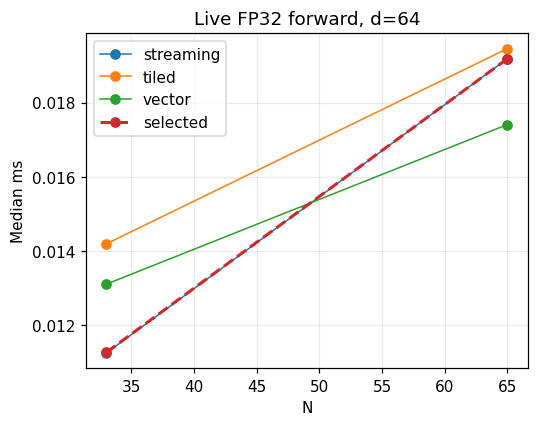

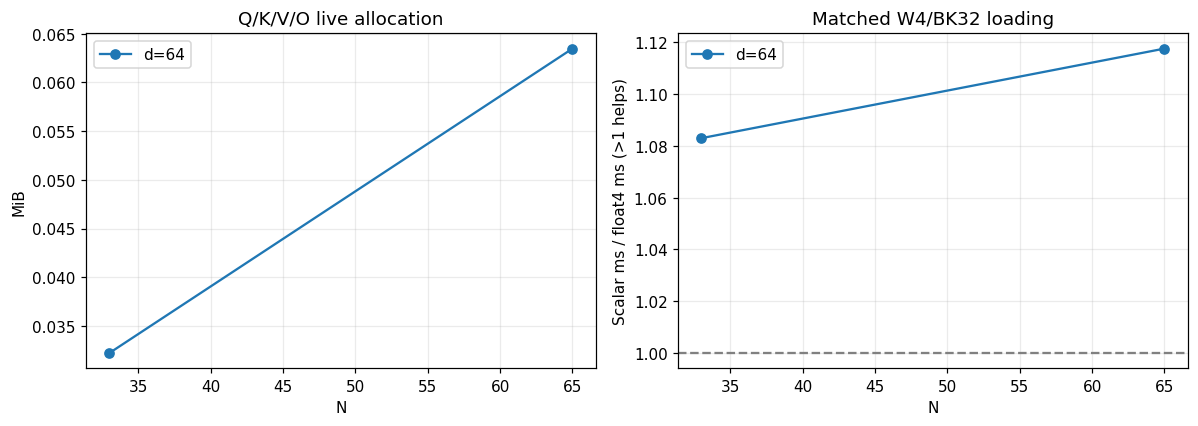

In [8]:
import numpy as np
import matplotlib.pyplot as plt
main=[r for r in tables["summary"] if r["experiment"]=="proposal"]
dimensions=sorted({int(r["d"]) for r in main})
fig,axes=plt.subplots(1,len(dimensions),figsize=(5*len(dimensions),4),squeeze=False)
for ax,d in zip(axes[0],dimensions):
    for variant in ("streaming","tiled","vector","selected"):
        rows=sorted([r for r in main if int(r["d"])==d and r["variant"]==variant],key=lambda r:int(r["N"]))
        ax.plot([int(r["N"]) for r in rows],[float(r["forward_median_ms"]) for r in rows],marker="o",label=variant,
                linestyle="--" if variant=="selected" else "-",linewidth=2 if variant=="selected" else 1)
    ax.set(title=f"Live FP32 forward, d={d}",xlabel="N",ylabel="Median ms");ax.grid(alpha=.25);ax.legend()
fig.tight_layout();plt.show()

fig,axes=plt.subplots(1,2,figsize=(11,4))
for d in dimensions:
    rows=sorted([r for r in selected if int(r["d"])==d],key=lambda r:int(r["N"]))
    axes[0].plot([int(r["N"]) for r in rows],[int(r["peak_workspace_allocated_bytes"])/2**20 for r in rows],marker="o",label=f"d={d}")
    pairs=[]
    for scalar in [r for r in main if int(r["d"])==d and r["variant"]=="tiled"]:
        vector=next(r for r in main if r["variant"]=="vector" and r["N"]==scalar["N"] and r["d"]==scalar["d"])
        pairs.append((int(scalar["N"]),float(scalar["forward_median_ms"])/float(vector["forward_median_ms"])))
    pairs.sort();axes[1].plot([x for x,y in pairs],[y for x,y in pairs],marker="o",label=f"d={d}")
axes[0].set(title="Q/K/V/O live allocation",xlabel="N",ylabel="MiB")
axes[1].set(title="Matched W4/BK32 loading",xlabel="N",ylabel="Scalar ms / float4 ms (>1 helps)");axes[1].axhline(1,color="gray",linestyle="--")
for ax in axes:ax.grid(alpha=.25);ax.legend()
fig.tight_layout();plt.show()

## 8. Compare to the historical full-grid measurement

This comparison appears for a **full** run only, and includes only rows where the frozen configuration matches the historical one. A ratio above one means your measured latency is higher. There is deliberately no hard timing assertion: case medians and IQR describe within-case variation, not a confidence interval across independent sessions. Different GPUs must not be compared as an optimisation speedup.

In [9]:
comparison=[]
if GRID=="full":
    for row in selected:
        old=next(r for r in reference_selected if r["N"]==row["N"] and r["d"]==row["d"])
        same=row["config"]==old["config"]
        comparison.append({"N":row["N"],"d":row["d"],"live_config":row["config"],"historical_config":old["config"],
            "live_ms":round(float(row["forward_median_ms"]),4),"historical_ms":round(float(old["forward_median_ms"]),4),
            "live/historical":round(float(row["forward_median_ms"])/float(old["forward_median_ms"]),3) if same else "different frozen config"})
    show_table(comparison)
else:
    print("Smoke is a pipeline check. Change GRID='full' for the historical shape-by-shape comparison.")

Smoke is a pipeline check. Change GRID='full' for the historical shape-by-shape comparison.


## 9. Verify offline regeneration, then read your report

Expected: all seven CSV hashes remain exactly identical after re-extraction from native records. Offline regeneration executes no CUDA kernels. The report and PNG/PDF figures are in your live output directory. This is a standalone B study; it neither measures A-versus-B speedups nor performs a same-machine A/B/C run.

In [10]:
def file_sha(path):return hashlib.sha256(Path(path).read_bytes()).hexdigest()
before={name:file_sha(OUTPUT/(name+".csv")) for name in schema.HEADERS}
sys.path.insert(0,str(PROJECT/"part_b/scripts"))
from export_results import export
repeat_audit=export(OUTPUT)
after={name:file_sha(OUTPUT/(name+".csv")) for name in schema.HEADERS}
assert before==after, "Offline extraction changed canonical data"
assert repeat_audit["passed"]==audit["passed"],"Evidence status changed unexpectedly"
print("Offline seven-table regeneration: PASS (byte-for-byte identical)")
print("Your complete output folder:",OUTPUT)
print("Report:",OUTPUT/"REPORT.md")
display(Markdown((OUTPUT/"REPORT.md").read_text(encoding="utf-8")))

Offline seven-table regeneration: PASS (byte-for-byte identical)
Your complete output folder: C:\Users\Yichun\Documents\Codex\2026-11-10\new-chat\flash_b_notebook_runs\20261110_014153_f507a4d3\results_smoke
Report: C:\Users\Yichun\Documents\Codex\2026-11-10\new-chat\flash_b_notebook_runs\20261110_014153_f507a4d3\results_smoke\REPORT.md


# Part B dense FlashAttention evaluation

FP32 contiguous BHNd inputs, FP32 accumulation/output. The shared C++ FP64 oracle validates every accepted timing case outside timing. Full small-case checks and sampled large-case checks are distinguished in correctness.csv. All outputs are checked for finiteness.

| N | d | Frozen configuration | Median ms | IQR ms | Explicit bytes |
|---|---|---|---|---|---|
| 33 | 64 | streaming_w4_k32 | 0.011264 | 0.003368 | 33792 |
| 65 | 64 | streaming_w4_k32 | 0.019184 | 0.000408 | 66560 |

The allocation ledger is 4 × B × H × N × d × sizeof(float), covering Q/K/V/O, with zero auxiliary global allocation. It is linear in N. Shared K/V/probability tiles and registers are per-block resources. Device free-memory deltas are observational and may be unreliable under Windows WDDM.

## Controlled loading comparison

Same W4/BK32 scalar and float4 kernels on the same generated tensors. Ratios below compare median latencies from separate sequential cases; close ratios are not statistically conclusive.

| N | d | Scalar ms | float4 ms | Scalar / float4 |
|---|---|---|---|---|
| 33 | 64 | 0.014192 | 0.013104 | 1.083 |
| 65 | 64 | 0.019456 | 0.017408 | 1.118 |

Validation records: 83 full and 0 sampled; 607,393 oracle-compared elements. Failed records: 0. All timed cases have matching validation records and input fingerprints.

The streaming and tiled kernels share the warp-per-query mapping. Tiling changes both K/V reuse and online update granularity; this comparison does not isolate one change. Tiled versus float4 with identical warps/key tile is the loading ablation. Candidate choices are frozen using geometric mean latency on tuning lengths only, with lexical ties. Main lengths include held-out lengths.

## Tuning and bottleneck interpretation

| d | Frozen winner | Tuning geometric mean ms | Slowest candidate | Tuning geometric mean ms |
|---|---|---|---|---|
| 64 | streaming_w4_k32 | 0.008986 | vector_w4_k64 | 0.012288 |

Larger shared tiles need not win: they increase per-block storage and can reduce occupancy. Cooperative loading adds barriers, probability-tile communication and warp reductions. Global-cache reuse can make the streaming baseline competitive. These are source/resource-based explanations to investigate; without fresh counters, the measurements do not establish DRAM bandwidth, bank conflicts or a definitive hardware bottleneck.

Five warmups and twenty CUDA-event samples measure complete fused forward only. Allocation, transfers, oracle, resource queries and file I/O are excluded. Fixed order, display-GPU contention, unmanaged clocks and within-case variation limit close-winner conclusions. No same-machine A/B/C performance comparison is claimed by this standalone run.

Fresh profiling requested: False. See audit.json for actual captures and safety checks. Missing counters must not be interpreted as zero traffic. AI-assisted implementation and analysis require member review and disclosure.


## Troubleshooting and interpretation

| Observation | Meaning / next step |
|---|---|
| `nvcc`, CMake or `cl` missing | Install/locate CUDA Toolkit, CMake or Visual Studio C++ tools; set `VCVARS64` when needed. |
| Unsupported MSVC version | Use a CUDA-supported compiler, or the explicit locally tested workaround in Settings. |
| `Program database manager mismatch` | Check the selected x64 compiler; this notebook uses embedded debug information. |
| Compute Sanitizer timeout | Tool did not establish safety. Disable optional checks for diagnostic data, or fix attachment outside the restricted session. |
| `ERR_NVGPUCTRPERM` | Nsight lacks GPU-counter permission. This is not a measured zero counter. Adjust permission through your normal NVIDIA administration workflow if you want profiles. |
| Numerical `FAIL`, nonfinite output, or a schema assertion | Stop and inspect the exact native JSON/command log. Do not increase tolerance to hide it. |
| `audit.passed=false` with the default settings | Expected: numerical checks passed, but sanitizer evidence is deliberately absent. |
| Different frozen winner or slower latency | Can reflect close candidates, clocks, display activity, compiler or hardware. Inspect timings/IQR rather than assuming a correctness bug. |
| N4096,d64 uses 128 MiB | Expected live Q/K/V/O allocation for B4/H8; auxiliary global storage is zero. |

The notebook and kernels were prepared with AI assistance and should be reviewed before academic submission. Keep this notebook's source and results separate from the different B implementation in your original checkout.